In [1]:
# Configure input files and output names.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(r'D:/eBATS')
DATA_DIR = PROJECT_ROOT / 'data' / 'C0019'
OUTPUT_DIR = PROJECT_ROOT / 'out' / 'C0019'
CASE_NAME = 'C0019_plot'
MODEL_FILE = DATA_DIR / 'C0019R00_PARK_APCM_1D_EVAL.xlsx'
CFD_MAX_FILE = DATA_DIR / 'sun_max.out'
CFD_MIN_FILE = DATA_DIR / 'sun_min.out'
FONT_SIZE = 12
TEMPERATURE_LIMITS_C = (22, 40)
ERROR_LIMITS_C = (-2, 2)
MARKER_NUMBER = 10

In [2]:
# Read existing temperatures and align all four curves by physical time.
def read_fluent_temperature(file_path, column_name):
    """Read a three-column Fluent temperature report and convert K to degC."""
    report = pd.read_csv(
        file_path, sep=r'\s+', skiprows=3,
        names=['time_step', 'temperature_K', 'time_s'], dtype=float,
    )
    report = report.sort_values('time_s', kind='stable').drop_duplicates(
        'time_s', keep='last',
    )
    report[column_name] = report['temperature_K'] - 273.15
    return report[['time_s', column_name]].reset_index(drop=True)


model = pd.read_excel(MODEL_FILE, sheet_name='Selected')[
    ['time_s', 'Tmax_C', 'Tmin_C']
].rename(columns={'Tmax_C': 'Tmax_1D_C', 'Tmin_C': 'Tmin_1D_C'})
model = model.sort_values('time_s', kind='stable').drop_duplicates('time_s', keep='last')
cfd_max = read_fluent_temperature(CFD_MAX_FILE, 'Tmax_CFD_C')
cfd_min = read_fluent_temperature(CFD_MIN_FILE, 'Tmin_CFD_C')
comparison = (
    model.merge(cfd_max, on='time_s', how='inner', validate='one_to_one')
    .merge(cfd_min, on='time_s', how='inner', validate='one_to_one')
    .sort_values('time_s').reset_index(drop=True)
)
comparison['error_max_C'] = comparison['Tmax_1D_C'] - comparison['Tmax_CFD_C']
comparison['error_min_C'] = comparison['Tmin_1D_C'] - comparison['Tmin_CFD_C']
time_s = comparison['time_s'].to_numpy()
print(f'1D samples: {len(model)}; CFD max: {len(cfd_max)}; CFD min: {len(cfd_min)}')
print(f'Aligned samples: {len(comparison)}; time range: {time_s[0]:g}-{time_s[-1]:g} s')
display(comparison.iloc[[0, -1]])

1D samples: 1294; CFD max: 1294; CFD min: 1294
Aligned samples: 1294; time range: 0-1293 s
      time_s  Tmax_1D_C  Tmin_1D_C  ...  Tmin_CFD_C   error_max_C   error_min_C
0          0  25.000000  25.000000  ...   25.000000 -2.330580e-12 -1.790568e-11
1293    1293  36.604919  35.382591  ...   35.265641  6.636791e-02  1.169505e-01

[2 rows x 7 columns]


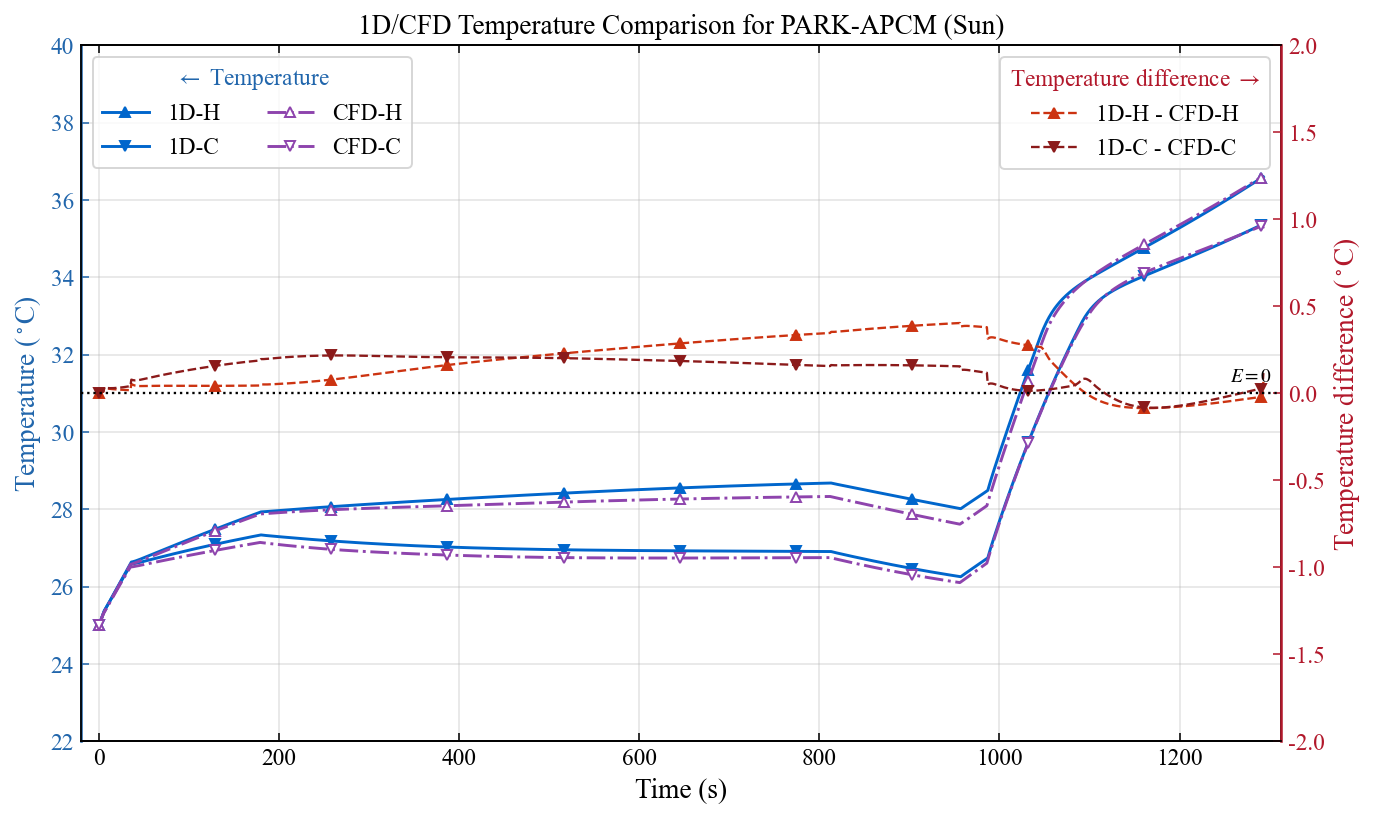

In [3]:
# Apply the scientific plotting style from the supplied reference code.
plt.rcParams.update({
    'font.family': 'Times New Roman',
    'mathtext.fontset': 'stix',
    'font.size': FONT_SIZE,
    'axes.labelsize': FONT_SIZE,
    'axes.titlesize': FONT_SIZE,
    'xtick.labelsize': FONT_SIZE,
    'ytick.labelsize': FONT_SIZE,
    'axes.linewidth': 0.9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'axes.unicode_minus': False,
})

temperature_style = {
    'Tmax_1D_C': dict(label='1D-H', color='#0066CC', ls='-', marker='^'),
    'Tmin_1D_C': dict(label='1D-C', color='#0066CC', ls='-', marker='v'),
    'Tmax_CFD_C': dict(label='CFD-H', color='#8E44AD', ls='-.', marker='^',
                       markerfacecolor='white'),
    'Tmin_CFD_C': dict(label='CFD-C', color='#8E44AD', ls='-.', marker='v',
                       markerfacecolor='white'),
}
error_style = {
    'error_max_C': dict(label='1D-H - CFD-H', color='#CC3311', ls='--', marker='^'),
    'error_min_C': dict(label='1D-C - CFD-C', color='#8B1A1A', ls='--', marker='v'),
}
left_color = '#2166AC'
right_color = '#B2182B'
marker_spacing = max(1, len(time_s) // MARKER_NUMBER)

fig, ax1 = plt.subplots(figsize=(10, 6))
for column, style in temperature_style.items():
    ax1.plot(time_s, comparison[column], markersize=5,
             markevery=marker_spacing, linewidth=1.5, **style)

ax2 = ax1.twinx()
for column, style in error_style.items():
    ax2.plot(time_s, comparison[column], markersize=5,
             markevery=marker_spacing, linewidth=1.2, **style)
ax2.axhline(0, color='black', linestyle=':', linewidth=1.2)
ax2.annotate(
    r'$E=0$', xy=(1.0, 0), xycoords=('axes fraction', 'data'),
    xytext=(-5, 4), textcoords='offset points', ha='right', va='bottom',
    fontsize=FONT_SIZE-2, color='black',
)

ax1.set_xlim(time_s[0]-20, time_s[-1]+20)
ax1.set_ylim(*TEMPERATURE_LIMITS_C)
ax2.set_ylim(*ERROR_LIMITS_C)
ax1.set_xlabel('Time (s)', fontsize=FONT_SIZE+2)
ax1.set_ylabel(r'Temperature ($^\circ\mathrm{C}$)',
               color=left_color, fontsize=FONT_SIZE+2)
ax2.set_ylabel(r'Temperature difference ($^\circ\mathrm{C}$)',
               color=right_color, fontsize=FONT_SIZE+2)
ax1.tick_params(axis='y', colors=left_color)
ax2.tick_params(axis='y', colors=right_color)
ax1.tick_params(top=True)
ax1.spines['left'].set_color(left_color)
ax1.spines['left'].set_linewidth(1.3)
ax2.spines['right'].set_color(right_color)
ax2.spines['right'].set_linewidth(1.3)
ax1.set_title('1D/CFD Temperature Comparison for PARK-APCM (Sun)', fontsize=FONT_SIZE+2)

legend_temperature = ax1.legend(loc='upper left', ncol=2, fontsize=FONT_SIZE)
legend_temperature.set_title(r'$\leftarrow$ Temperature', prop={'size': FONT_SIZE})
legend_temperature.get_title().set_color(left_color)
legend_error = ax2.legend(loc='upper right', ncol=1, fontsize=FONT_SIZE)
legend_error.set_title(r'Temperature difference $\rightarrow$', prop={'size': FONT_SIZE})
legend_error.get_title().set_color(right_color)
ax1.grid(alpha=0.35)
fig.tight_layout()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT_DIR / f'{CASE_NAME}.png', dpi=300, bbox_inches='tight')
fig.savefig(OUTPUT_DIR / f'{CASE_NAME}.pdf', bbox_inches='tight')
plt.show()

In [4]:
# Save the exact aligned data used for plotting.
comparison.to_csv(OUTPUT_DIR / f'{CASE_NAME}_data.csv', index=False)
print(f'Saved PNG, PDF and plotted data to: {OUTPUT_DIR}')
print(f'Maximum absolute hottest-temperature error: {comparison["error_max_C"].abs().max():.3f} degC')
print(f'Maximum absolute coldest-temperature error: {comparison["error_min_C"].abs().max():.3f} degC')

Saved PNG, PDF and plotted data to: D:\eBATS\out\C0019
Maximum absolute hottest-temperature error: 0.405 degC
Maximum absolute coldest-temperature error: 0.218 degC
